# Previsão de Manutenção

Projeto avaliativo do Módulo 1: prever falhas mecânicas (falha_maquina) a partir de dados de sensores.

## Fase 1: Análise Exploratória (EDA)

### Importação das bibliotecas e dados

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

#Gráfico com fundo claro e grade
sns.set_theme(style="whitegrid")

In [10]:
# Caminho do arquivo CSV
caminho = 'D:/Cursos/SCTEC/Carreira Tech/Módulo 1/Projeto Final/data/manutencao_preditiva.csv'

df = pd.read_csv(caminho)
df.head()

,udi,id_produto,tipo,temperatura_ar_k,temperatura_processo_k,velocidade_rotacao_rpm,torque_nm,desgaste_ferramenta_min,falha_maquina,falha_twf,falha_hdf,falha_pwf,falha_osf,falha_rnf
0,1,M14860,M,298.1,308.6,1551.0,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408.0,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498.0,49.4,5,0,0,0,0,0,0
3,4,L47183,L,NaN,NaN,NaN,NaN,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408.0,40.0,9,0,0,0,0,0,0


### 1.1 Dimensões, tipos de dados e resumo estatístico

In [14]:
linhas, colunas = df.shape
print(f"O dataset possui {linhas} linhas e {colunas} colunas.")

O dataset possui 10000 linhas e 14 colunas.


In [15]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   udi                      10000 non-null  int64  
 1   id_produto               10000 non-null  str    
 2   tipo                     10000 non-null  str    
 3   temperatura_ar_k         9500 non-null   float64
 4   temperatura_processo_k   9500 non-null   float64
 5   velocidade_rotacao_rpm   9500 non-null   float64
 6   torque_nm                9500 non-null   float64
 7   desgaste_ferramenta_min  10000 non-null  int64  
 8   falha_maquina            10000 non-null  int64  
 9   falha_twf                10000 non-null  int64  
 10  falha_hdf                10000 non-null  int64  
 11  falha_pwf                10000 non-null  int64  
 12  falha_osf                10000 non-null  int64  
 13  falha_rnf                10000 non-null  int64  
dtypes: float64(4), int64(8), str(2)
me

In [16]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
udi,10000.0,5000.500000,2886.895680,1.0,2500.75,5000.5,7500.25,10000.0
temperatura_ar_k,9500.0,300.002158,2.001689,295.3,298.30,300.1,301.50,304.5
temperatura_processo_k,9500.0,310.000895,1.486432,305.7,308.80,310.1,311.10,313.8
velocidade_rotacao_rpm,9500.0,1539.245263,180.273589,1168.0,1423.00,1504.0,1613.00,2886.0
torque_nm,9500.0,39.974168,9.995453,3.8,33.10,40.1,46.70,76.6
desgaste_ferramenta_min,10000.0,107.951000,63.654147,0.0,53.00,108.0,162.00,253.0
falha_maquina,10000.0,0.033900,0.180981,0.0,0.00,0.0,0.00,1.0
falha_twf,10000.0,0.004600,0.067671,0.0,0.00,0.0,0.00,1.0
falha_hdf,10000.0,0.011500,0.106625,0.0,0.00,0.0,0.00,1.0
falha_pwf,10000.0,0.009500,0.097009,0.0,0.00,0.0,0.00,1.0


#### Observações gerais

- **Valores ausentes:** `temperatura_ar_k`, `temperatura_processo_k`, `velocidade_rotacao_rpm` e `torque_nm` têm 9500 valores em 10.000 linhas, ou seja, 500 ausentes (5%) em cada uma. As colunas restantes estão completas.
- **Variável alvo desbalanceada:** a média de `falha_maquina` é 0,0339, pois a coluna só tem 0 e 1. Isso significa que 3,39% das máquinas falharam e 96,61% operaram normalmente. Um modelo que sempre previsse "sem falha" iria acertar 96,61%, então vai ser preciso balancear os dados de treino
- **Possíveis outliers:** em `velocidade_rotacao_rpm` o máximo (2886) está muito acima do percentil 75 (1613) e a cerca de 7,5 desvios padrão da média (1539). Os boxplots da Fase 2 vão confirmar isso.

### 1.2 Gráficos analíticos

#### Gráfico 1: distribuição da variável alvo

falha_maquina
0    9661
1     339
Name: count, dtype: int64
falha_maquina
0    96.61
1     3.39
Name: proportion, dtype: float64


C:\Users\Arthur\AppData\Local\Temp\ipykernel_21584\1138986194.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="falha_maquina", data=df, palette="Set2")


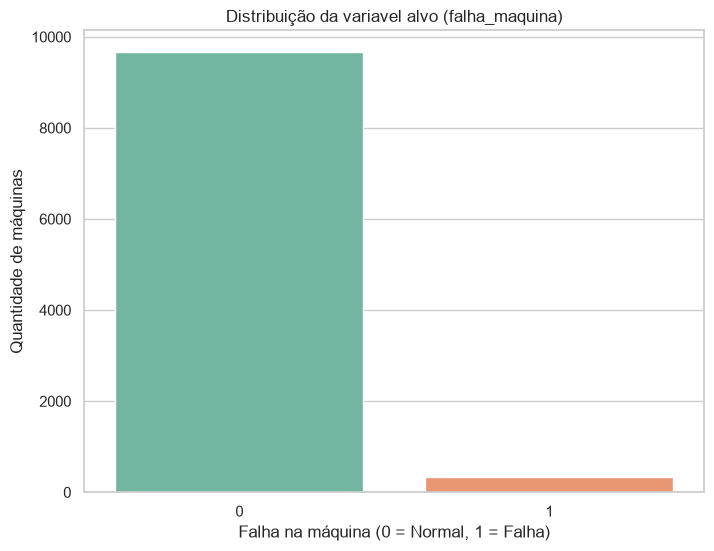

In [ ]:
#Quantidade e porcentagem de cada classe
print(df["falha_maquina"].value_counts())
print((df["falha_maquina"].value_counts(normalize=True)*100).round(2))

#Gráfico de barras
plt.figure(figsize=(8, 6))
sns.countplot(x="falha_maquina", data=df, palette="Set2")
plt.title("Distribuição da variável alvo (falha_maquina)")
plt.xlabel("Falha na máquina (0 = Normal, 1 = Falha)")
plt.ylabel("Quantidade de máquinas")
plt.show()

#### Gráfico 2: distribuição das variáveis preditoras

In [ ]:
variaveis_numericas = ['temperatura_ar_k', 
'temperatura_processo_k', 'velocidade_rotacao_rpm',
'torque_nm', 'desgaste_ferramenta_min']

# Grade de 2 linhas x 3 colunas de gráficos
fig, eixos = plt.subplots(2, 3, figsize=(15, 8))
eixos = eixos.flatten()

for eixo, coluna in zip(eixos, variaveis_numericas):
    sns.histplot(data=df, x=coluna, kde=True, bins=30, ax=eixo)
    eixo.set_title(f"Distribuição de {coluna}")

eixos[5].axis("off")

plt.tight_layout()
plt.show()

#### Gráfico 3: mapa de calor da correlação de Pearson

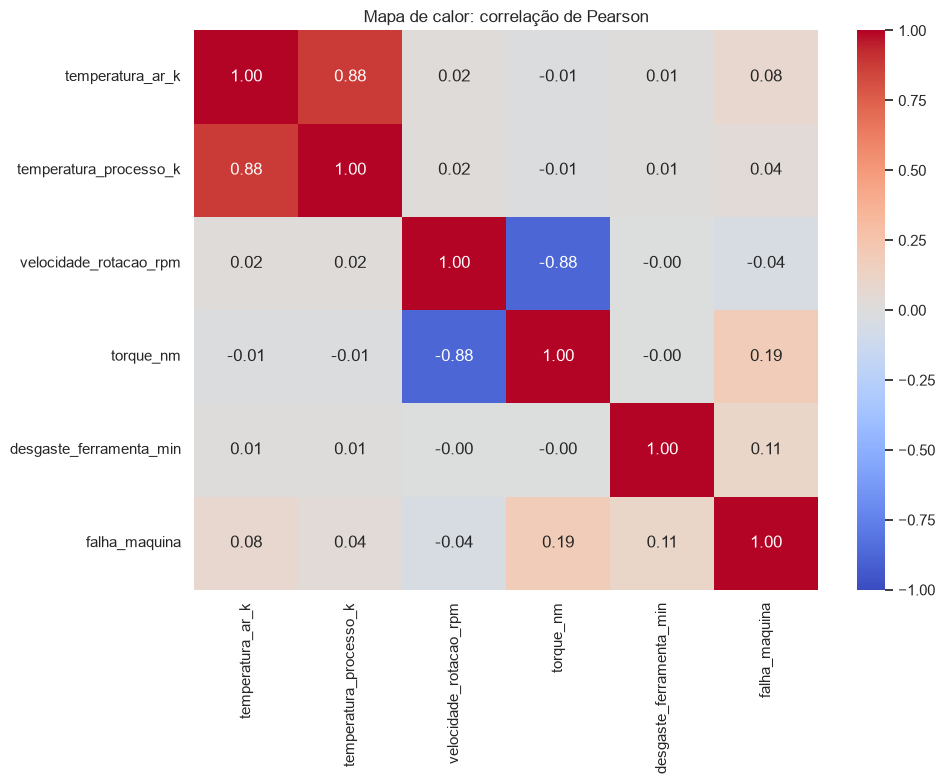

In [21]:
colunas_corr = ['temperatura_ar_k', 'temperatura_processo_k', 'velocidade_rotacao_rpm',
'torque_nm', 'desgaste_ferramenta_min', 'falha_maquina']

correlacao = df[colunas_corr].corr(method='pearson')

plt.figure(figsize=(10, 8))
sns.heatmap(correlacao, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,center=0)
plt.title("Mapa de calor: correlação de Pearson")
plt.tight_layout()
plt.show()